In [3]:
from astropy.table import Table, setdiff,join
from matplotlib import pyplot as plt
import numpy as np


In [4]:
alma_regions = Table.read('../output/tables/glimpse_s07/alma_regions_YSO.tbl',format='ascii.ipac')

class_I_60 = []
class_II_60 = []
#print(spitzer_sources['p1_class_I'][alma_regions['p1_class_I'] > 0])
class_0_20 = []

class_I_20 = []
class_II_20 = []

SURFD_to_nH2 = (
        
        6.022e23  # Avogadro's constant (N_A) [particles/mol]
        / 2.016  # molecular mass of n(H2) [g/mol]
    )


for region in alma_regions:

        L_M = np.log10(region['LUM'] / region['MASS'])
        L = region['LUM']
        M = region['MASS']
        dist = region['DIST_AG']
        T = region['TBOL']
        NH_2 = region['NODEC_SURFD']*SURFD_to_nH2

        #if region['class_I_60'] != 0 and region['class_I_60'] != 1:
        class_I_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_60']*100])
        #if region['class_II_60'] != 0 and region['class_II_60'] != 1:
        class_II_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_60']*100])
        #if region['class_0_20'] != 0:
        class_0_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_0_20']*100])
        #if region['class_I_20'] != 0:
        class_I_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_20']*100])
        #if region['class_II_20'] != 0:
        class_II_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_20']*100])

In [ ]:
alma_sources = Table.read('../output/tables/glimpse_s07/alma_sources_to_analyze.tbl',format='ascii.ipac')

print(alma_sources)

 ID       CLUMP            X         Y     ... p1_class_I p1_class_II p1_noclass
--- ------------------ --------- --------- ... ---------- ----------- ----------
  1             100132 897.03558  807.0044 ...         --          --         --
  2             100132 796.61502 862.99532 ...         --          --         --
  4             100244 468.07833 931.00007 ...         --          --         --
  1             100309 768.08734 459.99554 ...         --          --         --
  4             100309 637.45593 672.99884 ...         --          --         --
  8             100309 712.37732  683.0011 ...         --          --         --
  9             100309  642.2586 684.00324 ...         --          --         --
 10             100309 608.64019 683.00097 ...         --          --         --
 12             100309 696.04825 692.00105 ...         --          --         --
 16             100309 620.16646 729.99563 ...         --          --         --
...                ...      

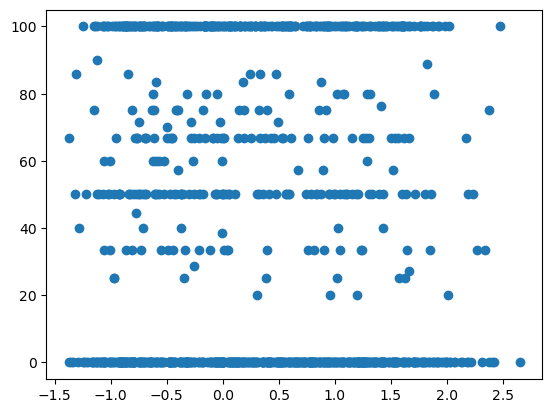

In [400]:
fig, ax = plt.subplots()

data_1 = [[x[0] for x in class_I_60],[x[-1] for x in class_I_60]]
data_2 = [[x[0] for x in class_II_60],[x[-1] for x in class_II_60]]
data_3 = [[x[0] for x in class_0_20],[x[-1] for x in class_0_20]]
data_4 = [[x[0] for x in class_I_20],[x[-1] for x in class_I_20]]
data_5 = [[x[0] for x in class_II_20],[x[-1] for x in class_II_20]]
ax.scatter(data_1[0],data_1[1])
#ax.scatter(data_2[0],data_2[1])

-1.371926893096385
2.6490899105719588
-1.371926893096385
2.6490899105719588


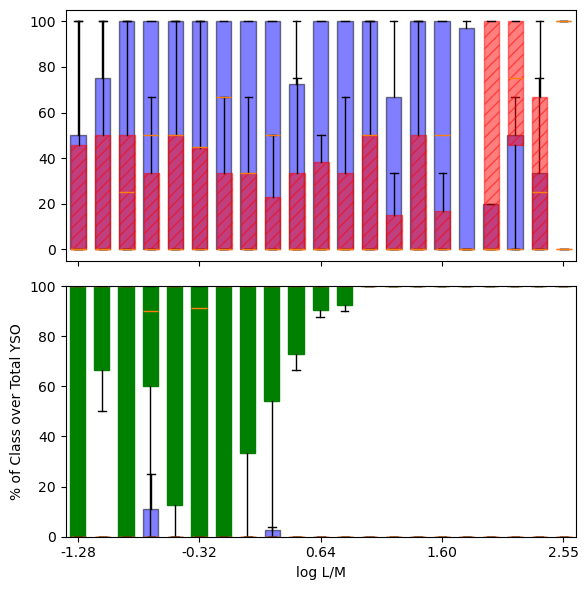

In [401]:

fig, axs = plt.subplots(2,1,figsize=(6,6),tight_layout=True,sharex=True)

for idx in range(2):

    if idx == 0:
        x1, y1 = np.array(data_1[0]), np.array(data_1[1])
        x2, y2 = np.array(data_2[0]), np.array(data_2[1])
    else:
        x1, y1 = np.array(data_4[0]), np.array(data_4[1])
        x2, y2 = np.array(data_5[0]), np.array(data_5[1])
    x3, y3 = np.array(data_3[0]), np.array(data_3[1])

    min = np.min([np.min(x1),np.min(x2),np.min(x3)])
    max = np.max([np.max(x1),np.max(x2),np.max(x3)])

    print(min)
    print(max)
    n_bins = 20
    step = (max-min)/(n_bins+1)
    bins = np.arange(min, max+step, step)

    groups1, groups2, groups3 = [], [], []
    pos1, pos2, pos3 = [], [], []

    offset = step/50  # spacing between boxplots

    for i in range(len(bins) - 1):
        mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
        mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
        mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])

        center = (bins[i] + bins[i+1]) / 2

        if np.sum(mask1) > 0:
            pos1.append(center)
            groups1.append(y1[mask1])
            
        if np.sum(mask2) > 0:
            pos2.append(center + offset)
            groups2.append(y2[mask2])
        if np.sum(mask3) > 0:
            pos3.append(center - offset)       
            groups3.append(y3[mask2])


    # Class I

    bp1 = axs[idx].boxplot(
        groups1,
        positions=pos1,
        widths=0.12,
        patch_artist=True,
        showfliers=False
    )

    for box in bp1['boxes']:
        box.set(facecolor='blue', alpha=0.5, edgecolor='black')

    # Class II

    bp2 = axs[idx].boxplot(
        groups2,
        positions=pos2,
        widths=0.12,
        patch_artist=True,
        showfliers=False
    )

    for box in bp2['boxes']:
        box.set(facecolor='red', alpha=0.5, edgecolor='red',hatch='///',linewidth=1)


# Class 0

bp0 = axs[1].boxplot(
    groups3,
    positions=pos3,
    widths=0.12,
    patch_artist=True,
    showfliers=False
)

for box in bp0['boxes']:
    box.set(facecolor='green', edgecolor='green',hatch='///',zorder=-1)


plt.xlim(min,max)
plt.ylim([0,100])

plt.xlabel('log L/M')
plt.ylabel('% of Class over Total YSO')

ticks = pos1[::5]

plt.xticks(ticks, [f"{t:.2f}" for t in ticks])


plt.show()

In [267]:
print(class_0_20)

[[np.float64(-0.7658434986502473), np.float64(220.1), np.float64(1283.7), np.float64(3670.0), np.float64(25.8), np.float64(2.56890873015873e+23), np.float64(0.0)], [np.float64(-1.2404912834206503), np.float64(68.9), np.float64(1198.7), np.float64(3630.0), np.float64(13.9), np.float64(3.3156845238095244e+23), np.float64(0.0)], [np.float64(-0.03689804154200282), np.float64(435.3), np.float64(473.9), np.float64(1860.0), np.float64(47.3), np.float64(6.362529761904762e+23), np.float64(0.0)], [np.float64(1.084519261623048), np.float64(2627.7), np.float64(216.3), np.float64(1780.0), np.float64(37.6), np.float64(3.7338789682539685e+23), np.float64(0.0)], [np.float64(-0.43227309023219107), np.float64(316.3), np.float64(855.8), np.float64(5280.0), np.float64(30.5), np.float64(1.881875e+23), np.float64(0.0)], [np.float64(-0.01102401186693966), np.float64(606.8), np.float64(622.4), np.float64(3530.0), np.float64(40.3), np.float64(2.6585218253968255e+23), np.float64(-300.0)], [np.float64(-0.4346112

In [268]:
print(class_II_60)

[[np.float64(-0.7658434986502473), np.float64(220.1), np.float64(1283.7), np.float64(3670.0), np.float64(25.8), np.float64(2.56890873015873e+23), np.float64(50.0)], [np.float64(-1.2404912834206503), np.float64(68.9), np.float64(1198.7), np.float64(3630.0), np.float64(13.9), np.float64(3.3156845238095244e+23), np.float64(50.0)], [np.float64(-0.03689804154200282), np.float64(435.3), np.float64(473.9), np.float64(1860.0), np.float64(47.3), np.float64(6.362529761904762e+23), np.float64(50.0)], [np.float64(1.084519261623048), np.float64(2627.7), np.float64(216.3), np.float64(1780.0), np.float64(37.6), np.float64(3.7338789682539685e+23), np.float64(50.0)], [np.float64(-0.43227309023219107), np.float64(316.3), np.float64(855.8), np.float64(5280.0), np.float64(30.5), np.float64(1.881875e+23), np.float64(50.0)], [np.float64(-0.01102401186693966), np.float64(606.8), np.float64(622.4), np.float64(3530.0), np.float64(40.3), np.float64(2.6585218253968255e+23), np.float64(50.0)], [np.float64(-0.4346

In [269]:
print( np.array(class_0_20) - np.array(class_II_60))

[[   0.    0.    0. ...    0.    0.  -50.]
 [   0.    0.    0. ...    0.    0.  -50.]
 [   0.    0.    0. ...    0.    0.  -50.]
 ...
 [   0.    0.    0. ...    0.    0.  -50.]
 [   0.    0.    0. ...    0.    0.  -50.]
 [   0.    0.    0. ...    0.    0. -350.]]


In [245]:
len(class_0_20)

1017

In [246]:
len(class_I_60)

1017

In [247]:
len(class_II_60)

1017

In [248]:
class_II_20

[[np.float64(-0.01102401186693966),
  np.float64(2.783045572114693),
  np.float64(2.7940695839816323),
  np.float64(3530.0),
  np.float64(40.3),
  np.float64(2.6585218253968255e+23),
  np.float64(20.0)],
 [np.float64(1.7034947063083985),
  np.float64(3.6519076720869994),
  np.float64(1.948412965778601),
  np.float64(2640.0),
  np.float64(55.5),
  np.float64(1.0454861111111111e+23),
  np.float64(25.0)],
 [np.float64(-0.4986821723630566),
  np.float64(2.48826861549546),
  np.float64(2.9869507878585164),
  np.float64(3570.0),
  np.float64(23.4),
  np.float64(4.45078373015873e+23),
  np.float64(16.666666666666664)],
 [np.float64(-0.2868332020427903),
  np.float64(1.9978230807457256),
  np.float64(2.2846562827885157),
  np.float64(3190.0),
  np.float64(22.0),
  np.float64(1.5831646825396828e+23),
  np.float64(40.0)],
 [np.float64(1.1756037840519975),
  np.float64(3.931859432806231),
  np.float64(2.7562556487542333),
  np.float64(3820.0),
  np.float64(42.5),
  np.float64(3.0468452380952385e+

In [249]:
len(class_I_60)

1017

In [ ]:
print(len())

1017


In [254]:
mask = np.array(class_I_60) > 0

print(len(mask[mask]))

6167


In [307]:
data_1[1]

[np.float64(50.0),
 np.float64(0.0),
 np.float64(100.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(60.0),
 np.float64(0.0),
 np.float64(66.66666666666666),
 np.float64(100.0),
 np.float64(0.0),
 np.float64(66.66666666666666),
 np.float64(25.0),
 np.float64(71.42857142857143),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(80.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(33.33333333333333),
 np.float64(60.0),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(50.0),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(85.71428571428571),
 np.float64(83.33333333333334),
 np.float64(100.0),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(50.0),
 np.float64(83.33333333333334),
 np.float64(50.0),
 np.float64(100.0),
 np.float64(100.0),
 np.float64(0.0),
 np.float64(100.0),
 np.float64(66.66666666666666),
 np.float64(90.0),
 np.float64(100.0),
 np.float64(100.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),

In [308]:
data_2[1]

[np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(40.0),
 np.float64(0.0),
 np.float64(33.33333333333333),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(33.33333333333333),
 np.float64(75.0),
 np.float64(28.57142857142857),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(20.0),
 np.float64(100.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(66.66666666666666),
 np.float64(40.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(50.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(14.285714285714285),
 np.float64(16.666666666666664),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(16.666666666666664),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(33.33333333333333),
 np.float64(10.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(50.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(14.28571

In [311]:
len(alma_regions[alma_regions['class_I_60'] > 0])

518

In [294]:
len(alma_regions[alma_regions['p1_class_II'] > 0])

0

In [367]:
len(alma_regions[alma_regions['class_I_60'] > 0])

518

In [312]:
len(alma_regions[alma_regions['class_II_60'] > 0])

338

In [313]:
len(alma_regions[alma_regions['class_0_20'] > 0])

822

In [314]:
len(alma_regions[alma_regions['class_I_20'] > 0])

148

In [315]:
len(alma_regions[alma_regions['class_II_20'] > 0])

7

L_M: -1.371926893096385, 2.6490899105719588
L: 0.9822712330395684, 5.719365515333529
M: 1.0644579892269184, 4.094289406693462
dist: 2.832508912706236, 4.201670179646581
T: 1.1172712956557642, 2.0542299098633974
NH_2: 21.776280219067235, 24.329556265204335


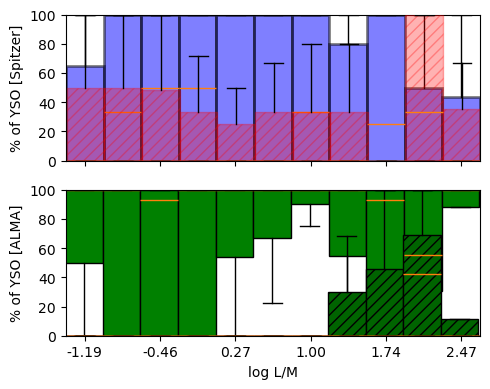

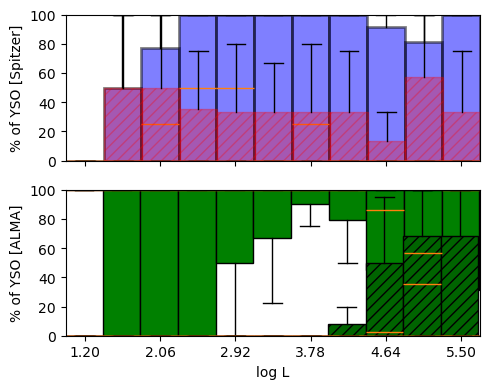

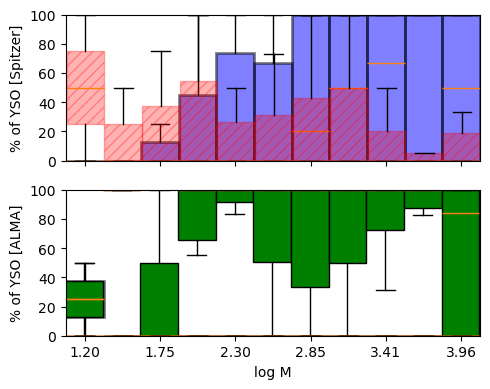

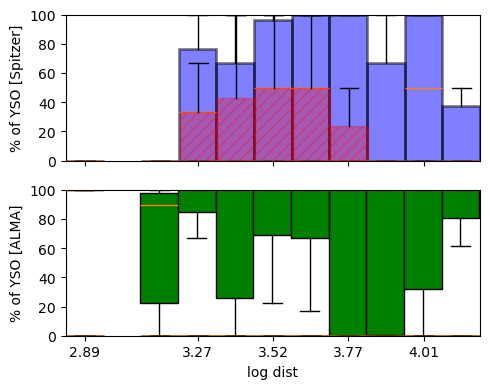

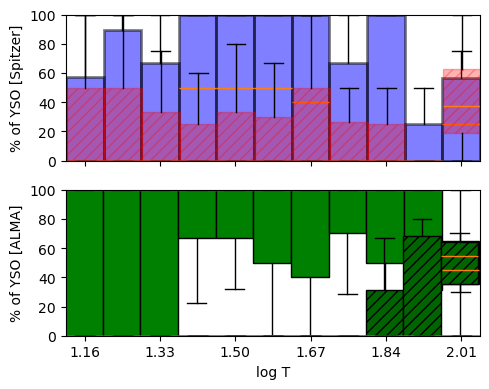

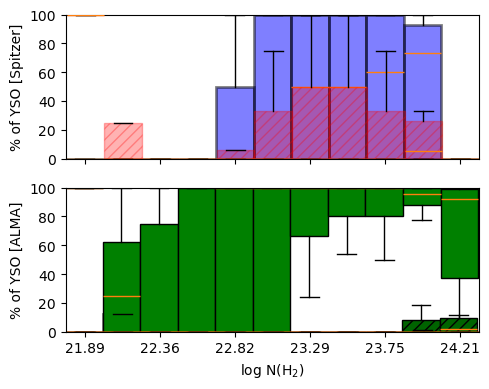

In [ ]:
cat='glimpse_s07'
skipflag = []

class_I_60 = []
class_II_60 = []
class_0_20 = []
class_I_20 = []
class_II_20 = []
radio_20 = []

for region in alma_regions:

    if (
          region['MASS'] == -999 or
          region['LUM'] == -999 or
          region['TBOL'] == -999 or 
          region['DIST_AG'] == -999 or
          region['NODEC_SURFD'] == -999
    ) or (
        (
          region['MASS'] == 0 or
          region['LUM'] == 0 or
          region['TBOL'] == 0 or 
          region['DIST_AG'] == 0 or
          region['NODEC_SURFD'] == 0
    )
    ):
        
        skipflag.append(region['INTERNAL_ID'])
        continue
      
    L_M = np.log10(region['LUM'] / region['MASS'])
    L = np.log10(region['LUM'])
    M = np.log10(region['MASS'])
    dist = np.log10(region['DIST_AG'])
    T = np.log10(region['TBOL'])
    NH_2 = np.log10(region['NODEC_SURFD']*SURFD_to_nH2)


    class_I_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_60']*100])
    class_II_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_60']*100])
    class_0_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_0_20']*100])
    class_I_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_20']*100])
    class_II_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_20']*100])
    radio_20.append([L_M,L,M,dist,T,NH_2, region['rat_radio_20']*100])

xlabels = ['log L/M', 'log L', 'log M', 'log dist', 'log T', 'log N(H$_2$)']

for idx, plot in enumerate(['L_M','L','M','dist','T','NH_2']):

    fig, axs = plt.subplots(2,1,figsize=(5,4),tight_layout=True,sharex=True)

    color_list = ['blue','red','lightgrey']

    for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20,radio_20],[class_I_20,class_II_20,class_0_20,radio_20]]):

        data_1 = [[x[idx] for x in data_set[0]],[x[-1] for x in data_set[0]]]
        data_2 = [[x[idx] for x in data_set[1]],[x[-1] for x in data_set[1]]]
        data_3 = [[x[idx] for x in data_set[2]],[x[-1] for x in data_set[2]]]
        data_4 = [[x[idx] for x in data_set[3]],[x[-1] for x in data_set[3]]]

        x1, y1 = np.array(data_1[0]),np.array(data_1[1])
        x2, y2 = np.array(data_2[0]), np.array(data_2[1])
        x3, y3 = np.array(data_3[0]), np.array(data_3[1])
        x4, y4 = np.array(data_4[0]), np.array(data_4[1])
        
        if idx2 == 0:
            min = np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)])
            max = np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)])
            n_bins = 10
            step = (max-min)/(n_bins+1)
            bins = np.arange(min, max+step, step)

        groups1, groups2, groups3, groups4 = [], [], [], []
        pos1, pos2, pos3, pos4 = [], [], [], []

        offset = step/50  # spacing between boxplots

        for i in range(len(bins) - 1):
            mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
            mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
            mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])
            mask4 = (x4 >= bins[i]) & (x4 < bins[i+1])
            
            center = (bins[i] + bins[i+1]) / 2

            if np.sum(mask1) > 0:
                pos1.append(center)
                groups1.append(y1[mask1])
                
            if np.sum(mask2) > 0:
                pos2.append(center + offset)
                groups2.append(y2[mask2])
            if np.sum(mask3) > 0:
                pos3.append(center - offset)       
                groups3.append(y3[mask3])
            if np.sum(mask4) > 0:
                pos4.append(center - 2*offset)       
                groups4.append(y4[mask4])

        # Class I

        bp1 = axs[idx2].boxplot(
            groups1,
            positions=pos1,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )

        for box in bp1['boxes']:
            box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

        # Class II

        bp2 = axs[idx2].boxplot(
            groups2,
            positions=pos2,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )

        for box in bp2['boxes']:
            box.set(facecolor='red', alpha=0.5, edgecolor='red',hatch='///',linewidth=1)

    print(f'{plot}: {np.min(x4)}, {np.max(x4)}')
    # Class 0

    bp0 = axs[1].boxplot(
        groups3,
        positions=pos3,
        widths=step,
        patch_artist=True,
        showfliers=False,
        zorder=1
    )

    for box in bp0['boxes']:
        box.set(facecolor='green', edgecolor='black')

    bp0_radio = axs[1].boxplot(
        groups4,
        positions=pos4,
        widths=step,
        patch_artist=True,
        showfliers=False,
        zorder=1
    )

    for box in bp0_radio['boxes']:
        box.set(facecolor='darkgreen', edgecolor='black',hatch='///')


    axs[0].set_xlim(min,max)
    axs[0].set_ylim([0,100])
    axs[1].set_ylim([0,100])

    axs[1].set_xlabel(f'{xlabels[idx]}')
    axs[0].set_ylabel(r'% of YSO [Spitzer]')
    axs[1].set_ylabel(r'% of YSO [ALMA]')

    ticks = pos1[::2]

    axs[1].set_xticks(ticks, [f"{t:.2f}" for t in ticks])
    if idx2 == 1:
        fig.savefig('../output/figures/'+cat+'/results_'+plot+'.pdf',format='pdf',dpi=300)

In [381]:
spitzer_sources = Table.read('../output/tables/glimpse_s07/spitzer_sources_to_analyze.tbl',format='ascii.ipac')
alma_regions = Table.read('../output/tables/glimpse_s07/alma_regions_to_analyze.tbl',format='ascii.ipac')

In [382]:
len(spitzer_sources['p1_class_I'][spitzer_sources['p1_class_I'] == 'True'])

1072

In [383]:
counter = 0
for region in alma_regions:
    region_id = region['INTERNAL_ID']
    counter = counter + len(spitzer_sources['p1_class_I'][(spitzer_sources['p1_class_I'] == 'True') & (spitzer_sources['internal_id_01'] == region_id)])

print(counter)

1072


In [390]:
print(np.sum(alma_regions['class_0_20']))

5960


In [416]:
for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20],[class_I_20,class_II_20,class_0_20]]):

    print(data_set[0][0])

[np.float64(-0.7658434986502473), np.float64(220.1), np.float64(1283.7), np.float64(3670.0), np.float64(25.8), np.float64(2.56890873015873e+23), np.float64(50.0)]
[np.float64(-0.7658434986502473), np.float64(220.1), np.float64(1283.7), np.float64(3670.0), np.float64(25.8), np.float64(2.56890873015873e+23), np.float64(0.0)]


In [436]:
for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20],[class_I_20,class_II_20,class_0_20]]):

    data_1 = [[x[1] for x in data_set[0]],[x[-1] for x in data_set[0]]]
    data_2 = [[x[1] for x in data_set[1]],[x[-1] for x in data_set[1]]]
    data_3 = [[x[1] for x in data_set[2]],[x[-1] for x in data_set[2]]]
    
    print(f'{idx2}:\n\n{np.array(data_1)}\n\n{data_2}\n\n{data_3}\n\n')
    print(f'{idx2}: \n\n {np.sum(np.where(np.isnan(np.array(data_1))))}')
    print(f'{idx2}:\n\n{np.min(data_1)}\n\n{np.min(data_2)}\n\n{np.min(data_3)}\n\n')

0:

[[220.1         68.9        435.3        ...   3.39112926   1.62838893
    2.97464983]
 [ 50.           0.         100.         ...  50.          50.
  100.        ]]

[[np.float64(220.1), np.float64(68.9), np.float64(435.3), np.float64(2627.7), np.float64(316.3), np.float64(606.8), np.float64(528.0), np.float64(181.8), np.float64(4486.5), np.float64(85.7), np.float64(307.8), np.float64(178.4), np.float64(99.5), np.float64(87.9), np.float64(8547.9), np.float64(15764.7), np.float64(76358.0), np.float64(869.6), np.float64(14954.8), np.float64(2023.6), np.float64(333.4), np.float64(174.8), np.float64(5745.4), np.float64(1056.6), np.float64(2297.0), np.float64(-999.0), np.float64(6285.8), np.float64(14055.0), np.float64(897.7), np.float64(7930.1), np.float64(30160.6), np.float64(329.0), np.float64(398.3), np.float64(76.5), np.float64(1265.5), np.float64(55134.6), np.float64(3679.9), np.float64(7982.1), np.float64(37411.7), np.float64(2867.6), np.float64(909.4), np.float64(203.7), np.fl

In [ ]:
len(data_1[0])

13191

In [4]:
print(tbl)

    region_id         dist_class_I     ... class_I class_II
----------------- -------------------- ... ------- --------
G340.7455-01.0021 0.007298674842445425 ...      16        5
           737787 0.009873454693467829 ...       9        0
            59900 0.008477970514395824 ...       9        1
           865468 0.006802858134818334 ...       8        1
            59799 0.008457280267435615 ...       8        4
           850981 0.009644871488715791 ...       7        0
           721509 0.004327915416211144 ...       7        3
            59561 0.007435256338843661 ...       7        0
            66261 0.004702944177026087 ...       7        0
            89378 0.005908569823233936 ...       6        4
              ...                  ... ...     ...      ...
           641751 0.004079607897547339 ...       2        5
            51020 0.006180668776997771 ...       2        6
            63437 0.004413677233087832 ...       2        4
           112942 0.003304760600253142 .

80


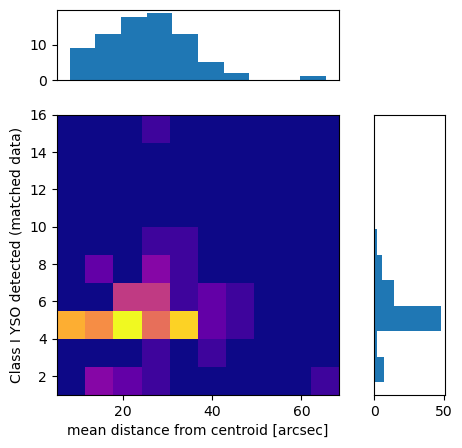

56


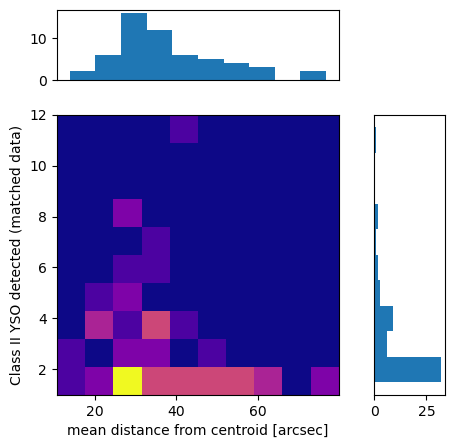

In [ ]:
n_regions = 1017
mode = 'total'
cat = 'glimpse_s07'

labels = ['Class I', 'Class II']
tbl = Table.read('../output/tables/'+cat+'/'+str(n_regions)+'_distance_'+str(mode)+'.tbl',format='ascii.ipac')
tbl = tbl[tbl['false_dist'] == 'False']




for idx,data in enumerate([['dist_class_I', 'class_I'],['dist_class_II','class_II']]):
    fig, axs = plt.subplots(2,2,figsize=(5,5),gridspec_kw={
        'width_ratios': [4, 1],
        'height_ratios': [1, 4]
    })

    xdata = np.array(tbl[data[0]][tbl[data[0]] != -999.0])
    ydata = np.array(tbl[data[1]][tbl[data[0]] != -999.0])
    print(len(xdata))
    xdata = xdata*3600

    axs[0][1].axis('off')
    axs[1][0].hist2d(xdata,ydata,cmap='plasma')

    axs[0][0].hist(xdata)
    axs[1][1].hist(ydata,orientation='horizontal')


    '''axs[0][0].set_xlim([0,40])
    axs[0][0].set_ylim([0,12])
    axs[1][1].set_ylim([0,4])
    axs[1][1].set_xlim([0,50])

    axs[1][0].set_xlim([0,40])
    axs[1][0].set_ylim([0,4])'''

    '''counts, _ = np.histogram(tbl['class_I']+tbl['class_II'],bins=range(0,np.max(tbl['class_I']+tbl['class_II'])+1,1))

    '''
    axs[1][0].set_xlabel('mean distance from centroid [arcsec]')
    axs[1][0].set_ylabel(labels[idx]+' YSO detected (matched data)')

    axs[0][0].tick_params(axis='x', bottom=False, labelbottom=False)
    axs[1][1].tick_params(axis='y', left=False, labelleft=False)
    axs[1][1].tick_params(axis='y', which='minor',left=False, labelleft=False)

    fig.savefig('../output/figures/'+cat+'/'+data[1]+'_distance_YSO.pdf',format='pdf',dpi=300)
    plt.show()
    plt.close()

1.8878642419325418: 79.78550152132644
1.8878642419325418: 39.882420906120814


C:\Users\Alex\AppData\Local\Temp\ipykernel_1156\2608512294.py:234: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect, connectors = axs[0].indicate_inset_zoom(axs[1],edgecolor='k',linestyle='--',linewidth=3)


6


C:\Users\Alex\AppData\Local\Temp\ipykernel_1156\2608512294.py:234: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  rect, connectors = axs[0].indicate_inset_zoom(axs[1],edgecolor='k',linestyle='--',linewidth=3)


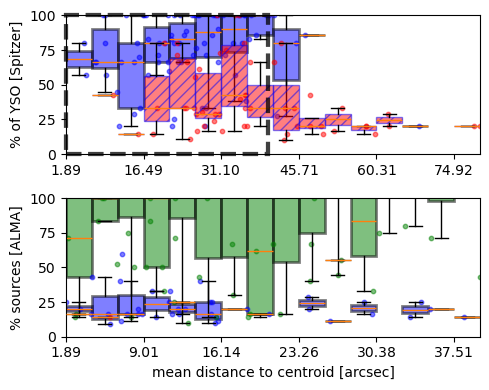

In [24]:
n_regions = 1017
mode = 'total'
cat = 'glimpse_s07'

labels = ['Class I', 'Class II']
tbl = Table.read('../output/tables/'+cat+'/'+str(n_regions)+'_distance_'+str(mode)+'.tbl',format='ascii.ipac')

tbl = tbl[tbl['false_dist'] == 'False']


aux = np.array(tbl['class_I']+tbl['class_II'])
    
count_I = np.array(tbl['class_I']) / aux  
count_II = np.array(tbl['class_II']) / aux

aux2 = np.array(tbl['class_0']+tbl['radio']+tbl['class_I_alma']+tbl['class_II_alma'])
    
count_0 = np.array(tbl['class_0']) / aux  
count_radio = np.array(tbl['radio']) / aux
count_I_alma = np.array(tbl['class_I_alma']) / aux  
count_II_alma = np.array(tbl['class_II_alma']) / aux


for idx, count in enumerate(count_I):
    if np.isnan(count):
        count_I[idx] = 0

for idx, count in enumerate(count_II):
    if np.isnan(count):
        count_II[idx] = 0

for idx, count in enumerate(count_0):
    if np.isnan(count):
        count_0[idx] = 0

for idx, count in enumerate(count_radio):
    if np.isnan(count):
        count_radio[idx] = 0

for idx, count in enumerate(count_I_alma):
    if np.isnan(count):
        count_I_alma[idx] = 0

for idx, count in enumerate(count_II_alma):
    if np.isnan(count):
        count_II_alma[idx] = 0



tbl['rat_class_I'] = count_I
tbl['rat_class_II'] = count_II

tbl['rat_class_0'] = count_0
tbl['rat_radio'] = count_radio
tbl['rat_class_I_alma'] = count_I_alma
tbl['rat_class_II_alma'] = count_II_alma

tbl.write('../output/tables/glimpse_s07/final_plot.tbl',format='ascii.ipac',overwrite=True)

fig, axs = plt.subplots(2,1,figsize=(5,4),tight_layout=True)

color_list = [['blue','red'], ['lightgrey','darkgrey']]

for idx, data_set in enumerate([
    [['dist_class_I','dist_class_II','dist_class_I_alma','dist_class_II_alma'],['rat_class_I','rat_class_II','rat_class_I_alma','rat_class_II_alma']],
    [['dist_class_I_alma','dist_class_II_alma','dist_class_0','dist_class_radio'],['rat_class_I_alma','rat_class_II_alma','rat_class_0','rat_radio',]]
    ]):

    if idx == 0:
        data = [
            [tbl[data_set[0][0]][tbl[data_set[0][0]] != -999], tbl[data_set[1][0]][tbl[data_set[0][0]] != -999]],
            [tbl[data_set[0][1]][tbl[data_set[0][1]] != -999], tbl[data_set[1][1]][tbl[data_set[0][1]] != -999]],
            [tbl[data_set[0][2]][tbl[data_set[0][2]] != -999], tbl[data_set[1][2]][tbl[data_set[0][2]] != -999]],
            [tbl[data_set[0][3]][tbl[data_set[0][3]] != -999], tbl[data_set[1][3]][tbl[data_set[0][3]] != -999]]
        ]
        
        x1, y1 = np.array(data[0][0])*3600,np.array(data[0][1])*100
        x2, y2 = np.array(data[1][0])*3600,np.array(data[1][1]) *100
        x3, y3 = np.array(data[2][0])*3600,np.array(data[2][1])*100
        x4, y4 = np.array(data[3][0])*3600, np.array(data[3][1]) *100
    else:
        data = [
            [tbl[data_set[0][0]][tbl[data_set[0][0]] != -999], tbl[data_set[1][0]][tbl[data_set[0][0]] != -999]],
            [tbl[data_set[0][1]][tbl[data_set[0][1]] != -999], tbl[data_set[1][1]][tbl[data_set[0][1]] != -999]],
            [tbl[data_set[0][2]][tbl[data_set[0][2]] != -999], tbl[data_set[1][2]][tbl[data_set[0][2]] != -999]],
            [tbl[data_set[0][3]][tbl[data_set[0][3]] != -999], tbl[data_set[1][3]][tbl[data_set[0][3]] != -999]]
        ]

        x1, y1 = np.array(data[0][0])*3600,np.array(data[0][1])*100
        x2, y2 = np.array(data[1][0])*3600,np.array(data[1][1]) *100
        x3, y3 = np.array(data[2][0])*3600,np.array(data[2][1])*100
        x4, y4 = np.array(data[3][0])*3600, np.array(data[3][1]) *100

    if idx == 0:
        min = np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)])
        max = np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)])
    if idx == 1:
        min_2 = np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)])
        max_2 = np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)])

        min = np.min([min,min_2])
        max = np.min([max,max_2])
    print(f'{min}: {max}')
    n_bins = 15
    step = (max-min)/(n_bins+1)
    bins = np.arange(min, max+step, step)

    groups1, groups2,groups3, groups4 = [], [], [], []
    pos1, pos2, pos3, pos4 = [], [], [], []

    offset = step/50  # spacing between boxplots

    for i in range(len(bins) - 1):
        mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
        mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
        mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])
        mask4 = (x4 >= bins[i]) & (x4 < bins[i+1])

        center = (bins[i] + bins[i+1]) / 2

        if np.sum(mask1) > 0:
            pos1.append(center)
            groups1.append(y1[mask1])
        if np.sum(mask2) > 0:
            pos2.append(center)
            groups2.append(y2[mask2])
        if np.sum(mask3) > 0:
            pos3.append(center)
            groups3.append(y3[mask3])
        if np.sum(mask4) > 0:
            pos4.append(center)
            groups4.append(y4[mask4])

    
    
    if idx == 0:

        # Class I 

        bp1 = axs[0].boxplot(
            groups1,
            positions=pos1,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )

        for box in bp1['boxes']:
            box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

        axs[0].scatter(x1,y1,color='blue',s=10,alpha=0.5)
        # Class II
        
        bp2 = axs[0].boxplot(
            groups2,
            positions=pos2,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )
        
        for box in bp2['boxes']:
            box.set(facecolor='red', alpha=0.5, edgecolor=color_list[idx][0],hatch='///',linewidth=1)
        axs[0].scatter(x2,y2,color='red',s=10,alpha=0.5)
    if idx == 1:
        
        # Class I ALMA

        bp1 = axs[1].boxplot(
            groups1,
            positions=pos1,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )

        for box in bp1['boxes']:
            box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)
        axs[1].scatter(x1,y1,color='blue',s=10,alpha=0.5)
        
        # Class II ALMA

        bp2 = axs[1].boxplot(
            groups2,
            positions=pos2,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )
        
        for box in bp2['boxes']:
            box.set(facecolor='red', alpha=0.5, edgecolor=color_list[idx][0],hatch='///',linewidth=1)
        axs[1].scatter(x2,y2,color='red',s=10,alpha=0.5)
        
        # Class 0

        bp3 = axs[idx].boxplot(
            groups3,
            positions=pos3,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=2
        )
        axs[1].scatter(x3,y3,color='green',s=10,alpha=0.5)
        for box in bp3['boxes']:
            box.set(facecolor='green', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

        # radio

        bp4 = axs[idx].boxplot(
            groups4,
            positions=pos4,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=3
        )
        axs[1].scatter(x4,y4,color='darkgreen',s=10,alpha=0.5)
        for box in bp4['boxes']:
            box.set(facecolor='darkgreen', alpha=0.5, edgecolor='black',hatch='///',linewidth=1,zorder=2)

    axs[idx].set_xlim(min,max)
    axs[0].set_ylim([0,100])
    axs[1].set_ylim([0,100])
    
    axs[1].set_xlabel('mean distance to centroid [arcsec]')

    if idx == 0:
        axs[0].set_ylabel(r'% of YSO [Spitzer]')
    else:
        axs[1].set_ylabel(r'% sources [ALMA]')
    
    rect, connectors = axs[0].indicate_inset_zoom(axs[1],edgecolor='k',linestyle='--',linewidth=3)

    

    for c in connectors:
        c.set_visible(False)
        c.set_linestyle('--')
        c.set_linewidth(3)


    ticks = bins[::3]

    axs[idx].set_xticks(ticks, [f"{t:.2f}" for t in ticks])

fig.savefig('../output/figures/'+cat+'/results_distance_YSO.pdf',format='pdf',dpi=300)

In [65]:
print(sum(alma_regions['radio_20']))

60


In [128]:
tbl[data_set[1][1]][tbl[data_set[0][1]]

_IncompleteInputError: incomplete input (711261313.py, line 1)

In [127]:
float(tbl[data_set[0][1]][tbl[data_set[0][1]] != '-999'])

C:\Users\Alex\AppData\Local\Temp\ipykernel_12704\2311210900.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  float(tbl[data_set[0][1]][tbl[data_set[0][1]] != '-999'])


0.0016581490549440097

In [139]:
(np.array(float(['2','1']))*3600)[0]

TypeError: float() argument must be a string or a real number, not 'list'

In [89]:
alma_sources = Table.read('../output/tables/glimpse_s07/ALMADEBUG.tbl',format='ascii.ipac')
counter_class_0 = 0
counter_radio = 0
for source in alma_sources:
    
    if source['HAS_SPITZER'] == 'False':

        if source['RADIO_MATCH'] == 0 :

            counter_class_0 = counter_class_0 +1
        else:
            counter_radio = counter_radio +1

print(f'{counter_class_0}, {counter_radio}')

18, 0


In [141]:
for idx, data_set in enumerate([
    [['dist_class_I','dist_class_II','dist_class_I_alma','dist_class_II_alma'],['rat_class_I','rat_class_II','rat_class_I_alma','rat_class_II_alma']],
    [['dist_class_I_alma','dist_class_II_alma','dist_class_0','dist_class_radio'],['rat_class_I_alma','rat_class_II_alma','rat_class_0','rat_radio',]]
    ]):

    x2, y2 = np.array((data[1][0])).astype(float)*3600,np.array(data[1][1]) *100
    

    print(f'{x1}: {y1}')
    print(f'{x2}: {y2}')

[ 5.9317393  38.42877142 15.53616098 15.24544934  7.46980041 15.63585343
 12.22657251 15.87247367 20.52753357 10.18117571 24.13472017  5.70834192
 33.49458489 24.20857299 14.18658313 12.84254062  8.49616976  8.84512384
  7.03671364 11.38686722 29.24161319  3.20449915  6.8719649  15.32785538
 12.1749866   6.9730481   8.47843605  4.27008733  4.151366   34.43631314
 15.1056057  18.50719379 35.27074948 29.96922607 11.40976147  9.81728826
  1.88786424 26.11220306 11.61225388]: [ 9.52380952 14.28571429 10.         16.66666667 16.66666667 14.28571429
 16.66666667 11.11111111 16.66666667 14.28571429 28.57142857 16.66666667
 14.28571429 20.         40.         20.         16.66666667 16.66666667
 60.         25.         25.         20.         40.         25.
 20.         11.11111111 20.         42.85714286 16.66666667 25.
 25.         20.         20.         16.66666667 33.33333333 33.33333333
 25.         11.11111111 16.66666667]
[5.9693366]: [14.28571429]
[ 5.9317393  38.42877142 15.53616098

In [34]:
aux = np.array([2,0])+np.array([3,0])
print(aux)
aux[aux == 0] = 1
print(aux)

[5 0]
[5 1]


In [ ]:
def function(alma_regions):
    
    # MARK: L/M, L, M, T, DIST, N(H_2)

    class_I_60 = []
    class_II_60 = []
    class_0_20 = []
    class_I_20 = []
    class_II_20 = []
    radio_20 = []

    SURFD_to_nH2 = (
        
        6.022e23  # Avogadro's constant (N_A) [particles/mol]
        / 2.016  # molecular mass of n(H2) [g/mol]
    )

    for region in alma_regions:

        if (
            region['MASS'] == -999 or
            region['LUM'] == -999 or
            region['TBOL'] == -999 or 
            region['DIST_AG'] == -999 or
            region['NODEC_SURFD'] == -999
        ):
            continue
        
        L_M = np.log10(region['LUM'] / region['MASS'])
        L = np.log10(region['LUM'])
        M = np.log10(region['MASS'])
        dist = np.log10(region['DIST_AG'])
        T = np.log10(region['TBOL'])
        NH_2 = np.log10(region['NODEC_SURFD']*SURFD_to_nH2)


        class_I_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_60']*100])
        class_II_60.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_60']*100])
        class_0_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_0_20']*100])
        class_I_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_I_20']*100])
        class_II_20.append([L_M,L,M,dist,T,NH_2, region['rat_class_II_20']*100])
        radio_20.append([L_M,L,M,dist,T,NH_2, region['rat_radio_20']*100])

    xlabels = [r'log L/M [L$_\odot$/M$_\odot$]', r'log L [L$_\odot$]', r'log M [M$_\odot$]', 'log distance [pc]', r'log T$_{\text{bol}}$ [K]', r'log N(H$_2$) [cm$^{-2}$]']

    for idx, plot in enumerate(['L_M','L','M','dist','T','NH_2']):

        fig, axs = plt.subplots(2,1,figsize=(5,4),tight_layout=True,sharex=True)

        for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20, radio_20],[class_I_20,class_II_20,class_0_20, radio_20]]):

            data_1 = [[x[idx] for x in data_set[0]],[x[-1] for x in data_set[0]]]
            data_2 = [[x[idx] for x in data_set[1]],[x[-1] for x in data_set[1]]]
            data_3 = [[x[idx] for x in data_set[2]],[x[-1] for x in data_set[2]]]
            data_4 = [[x[idx] for x in data_set[3]],[x[-1] for x in data_set[3]]]

            x1, y1 = np.array(data_1[0]),np.array(data_1[1])
            x2, y2 = np.array(data_2[0]), np.array(data_2[1])
            x3, y3 = np.array(data_3[0]), np.array(data_3[1])
            x4, y4 = np.array(data_4[0]), np.array(data_4[1])
            

            if idx2 == 0:
                min = round(10*np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)]))/10
                max = round(10*np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)]))/10
                n_bins = 12
                step = (max-min)/(n_bins)
                bins = np.arange(min, max+step, step)

            

            groups1, groups2, groups3,groups4 = [], [], [], []
            pos1, pos2, pos3, pos4 = [], [], [], []

            #offset = step/50  # spacing between boxplots

            offset = 0

            for i in range(len(bins) - 1):
                mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
                mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
                mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])
                mask4 = (x4 >= bins[i]) & (x4 < bins[i+1])

                center = (bins[i] + bins[i+1]) / 2

                if np.sum(mask1) > 0:
                    pos1.append(center)
                    groups1.append(y1[mask1])
                    
                if np.sum(mask2) > 0:
                    pos2.append(center + offset)
                    groups2.append(y2[mask2])
                if np.sum(mask3) > 0:
                    pos3.append(center - offset)       
                    groups3.append(y3[mask3])
                if np.sum(mask4) > 0:
                    pos4.append(center - 2*offset)       
                    groups4.append(y4[mask4])


            # Class I

            bp1 = axs[idx2].boxplot(
                groups1,
                positions=pos1,
                widths=step,
                patch_artist=True,
                showfliers=False,
                zorder=2
            )
            axs[idx2].scatter(x1,y1,color='blue',s=10,alpha=0.6,zorder=20)
            for box in bp1['boxes']:
                box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

            # Class II

            bp2 = axs[idx2].boxplot(
                groups2,
                positions=pos2,
                widths=step,
                patch_artist=True,
                showfliers=False,
                zorder=3
            )
            axs[idx2].scatter(x2,y2,color='red',s=10,alpha=0.6,zorder=20)
            for box in bp2['boxes']:
                box.set(facecolor='red', alpha=0.4, edgecolor='red',hatch='///',linewidth=1,zorder=1)


        # Class 0

        bp0 = axs[1].boxplot(
            groups3,
            positions=pos3,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=1
        )
        
        for box in bp0['boxes']:
            box.set(facecolor='limegreen', alpha=0.5,edgecolor='black')
        axs[1].scatter(x3,y3,color='darkgreen',s=10,alpha=0.3,zorder=20)

        bp3 = axs[1].boxplot(
            groups4,
            positions=pos4,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=0
        )
        axs[1].scatter(x4,y4,color='orange',s=10,alpha=0.6,zorder=20)
        for box in bp3['boxes']:
            box.set(facecolor='gold', alpha=0.4,edgecolor='black',hatch='///')


        axs[0].set_xlim(min,max)
        axs[0].set_ylim([-5,105])
        axs[1].set_ylim([-5,105])

        axs[1].set_xlabel(f'{xlabels[idx]}')
        axs[0].set_ylabel(r'% of YSO [Spitzer]')
        axs[1].set_ylabel(r'% of YSO [ALMA]')

        ticks = bins[::2]

        axs[1].set_xticks(ticks, [f"{t:.2f}" for t in ticks])
        if idx2 == 1:
            fig.savefig('../output/figures/'+cat+'/results_'+plot+'.pdf',format='pdf',dpi=300)
            plt.show()
            plt.close()

In [220]:
alma_regions = Table.read('../output/tables/glimpse_s07/alma_regions_YSO.tbl',format='ascii.ipac')

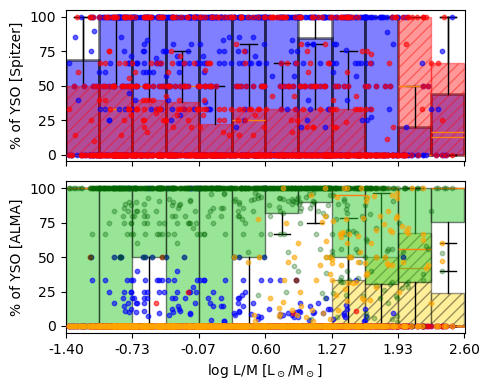

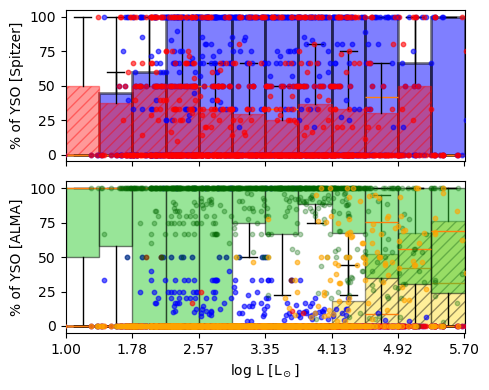

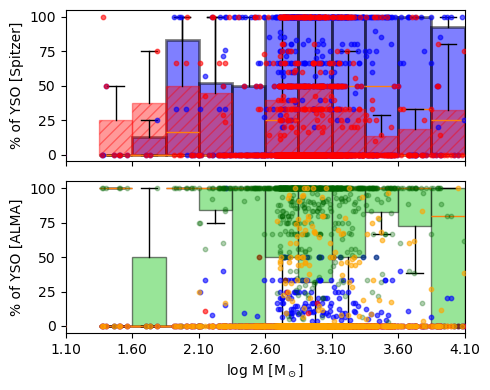

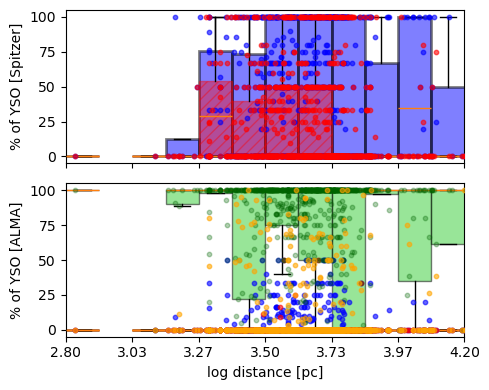

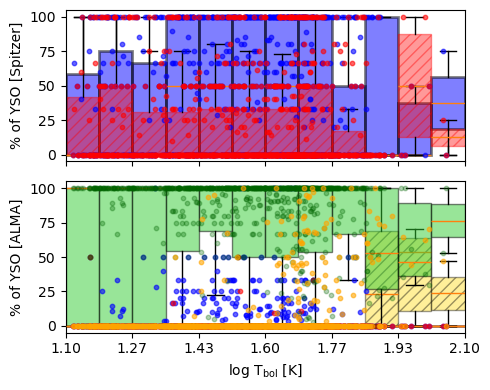

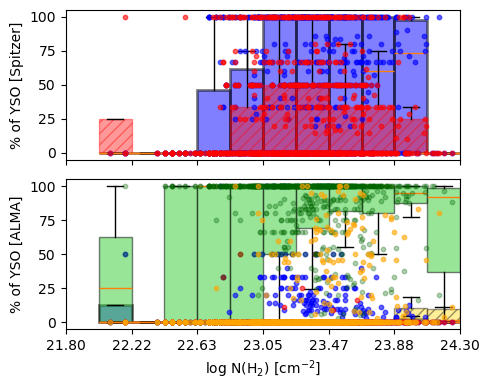

In [223]:

function(alma_regions)

In [80]:
tbl = Table.read('../output/tables/glimpse_s07/1017_distance_total.tbl',format='ascii.ipac')
tbl['region_id'][tbl['false_dist'] == 'True']

881644
57335
56634
765992
133522
65099
128764
744588
743353
737579
131513


In [ ]:
def function(alma_regions):
    
    tbl = Table.read('../output/tables/glimpse_s07/1017_distance_total.tbl',format='ascii.ipac')

    #tbl = tbl[tbl['false_dist'] == 'False']

    

    aux = np.array(tbl['class_I'])+np.array(tbl['class_II'])

    aux[aux == 0] = 1

    count_I = np.array(tbl['class_I']) / aux  
    count_II = np.array(tbl['class_II']) / aux

    aux2 = np.array(tbl['class_0'])+np.array(tbl['radio'])+np.array(tbl['class_I_alma'])+np.array(tbl['class_II_alma'])

    aux2[aux2 == 0] = 1  
    
    count_0 = np.array(tbl['class_0']) / aux2  
    count_radio = np.array(tbl['radio']) / aux2
    count_I_alma = np.array(tbl['class_I_alma']) / aux2  
    count_II_alma = np.array(tbl['class_II_alma']) / aux2


    for idx, count in enumerate(count_I):
        if np.isnan(count):
            count_I[idx] = 0

    for idx, count in enumerate(count_II):
        if np.isnan(count):
            count_II[idx] = 0

    for idx, count in enumerate(count_0):
        if np.isnan(count):
            count_0[idx] = 0

    for idx, count in enumerate(count_radio):
        if np.isnan(count):
            count_radio[idx] = 0

    for idx, count in enumerate(count_I_alma):
        if np.isnan(count):
            count_I_alma[idx] = 0

    for idx, count in enumerate(count_II_alma):
        if np.isnan(count):
            count_II_alma[idx] = 0



    tbl['rat_class_I'] = count_I
    tbl['rat_class_II'] = count_II

    tbl['rat_class_0'] = count_0
    tbl['rat_radio'] = count_radio
    tbl['rat_class_I_alma'] = count_I_alma
    tbl['rat_class_II_alma'] = count_II_alma
    
    
    
    print(len(tbl))
    
    # MARK: L/M, L, M, T, DIST, N(H_2)

    class_I_60 = []
    class_II_60 = []
    class_0_20 = []
    class_I_20 = []
    class_II_20 = []
    radio_20 = []

    SURFD_to_nH2 = (
        
        6.022e23  # Avogadro's constant (N_A) [particles/mol]
        / 2.016  # molecular mass of n(H2) [g/mol]
    )

    for region in alma_regions:
        region_id = region['INTERNAL_ID']
        if (
            region['MASS'] == -999 or
            region['LUM'] == -999 or
            region['TBOL'] == -999 or 
            region['DIST_AG'] == -999 or
            region['NODEC_SURFD'] == -999
        ):
            continue
        
        L_M = np.log10(region['LUM'] / region['MASS'])
        L = np.log10(region['LUM'])
        M = np.log10(region['MASS'])
        dist = np.log10(region['DIST_AG'])
        T = np.log10(region['TBOL'])
        NH_2 = np.log10(region['NODEC_SURFD']*SURFD_to_nH2)


        class_I_60.append([L_M,L,M,dist,T,NH_2, (tbl['rat_class_I'][tbl['region_id'] == region_id])[0] *100])
        class_II_60.append([L_M,L,M,dist,T,NH_2, (tbl['rat_class_II'][tbl['region_id'] == region_id])[0]*100])

        class_0_20.append([L_M,L,M,dist,T,NH_2, (tbl['rat_class_0'][tbl['region_id'] == region_id])[0]*100])
        class_I_20.append([L_M,L,M,dist,T,NH_2, (tbl['rat_class_I_alma'][tbl['region_id'] == region_id])[0]*100])
        class_II_20.append([L_M,L,M,dist,T,NH_2,(tbl['rat_class_II_alma'][tbl['region_id'] == region_id])[0]*100])
        radio_20.append([L_M,L,M,dist,T,NH_2, (tbl['rat_radio'][tbl['region_id'] == region_id])[0]*100])

    xlabels = [r'log L/M [L$_\odot$/M$_\odot$]', r'log L [L$_\odot$]', r'log M [M$_\odot$]', 'log distance [pc]', r'log T$_{\text{bol}}$ [K]', r'log N(H$_2$) [cm$^{-2}$]']

    for idx, plot in enumerate(['L_M','L','M','dist','T','NH_2']):

        fig, axs = plt.subplots(2,1,figsize=(5,4),tight_layout=True,sharex=True)

        color_list = ['blue','red','lightgrey']

        for idx2,data_set in enumerate([[class_I_60,class_II_60,class_0_20, radio_20],[class_I_20,class_II_20,class_0_20, radio_20]]):

            data_1 = [[x[idx] for x in data_set[0]],[x[-1] for x in data_set[0]]]
            data_2 = [[x[idx] for x in data_set[1]],[x[-1] for x in data_set[1]]]
            data_3 = [[x[idx] for x in data_set[2]],[x[-1] for x in data_set[2]]]
            data_4 = [[x[idx] for x in data_set[3]],[x[-1] for x in data_set[3]]]

            x1, y1 = np.array(data_1[0]),np.array(data_1[1])
            x2, y2 = np.array(data_2[0]), np.array(data_2[1])
            x3, y3 = np.array(data_3[0]), np.array(data_3[1])
            x4, y4 = np.array(data_4[0]), np.array(data_4[1])

            

            if idx2 == 0:
                min = np.min([np.min(x1),np.min(x2),np.min(x3),np.min(x4)])
                max = np.max([np.max(x1),np.max(x2),np.max(x3),np.max(x4)])
                n_bins = 10
                step = (max-min)/(n_bins+1)
                bins = np.arange(min, max+step, step)
            x1[y1 == 0] = -999
            groups1, groups2, groups3,groups4 = [], [], [], []
            pos1, pos2, pos3, pos4 = [], [], [], []

            #offset = step/50  # spacing between boxplots

            offset = 0

            for i in range(len(bins) - 1):
                mask1 = (x1 >= bins[i]) & (x1 < bins[i+1])
                mask2 = (x2 >= bins[i]) & (x2 < bins[i+1])
                mask3 = (x3 >= bins[i]) & (x3 < bins[i+1])
                mask4 = (x4 >= bins[i]) & (x4 < bins[i+1])

                center = (bins[i] + bins[i+1]) / 2

                if np.sum(mask1) > 0:
                    pos1.append(center)
                    groups1.append(y1[mask1])
                    
                if np.sum(mask2) > 0:
                    pos2.append(center + offset)
                    groups2.append(y2[mask2])
                if np.sum(mask3) > 0:
                    pos3.append(center - offset)       
                    groups3.append(y3[mask3])
                if np.sum(mask4) > 0:
                    pos4.append(center - 2*offset)       
                    groups4.append(y4[mask4])


            # Class I
            if idx2 == 0:

                bp1 = axs[0].boxplot(
                    groups1,
                    positions=pos1,
                    widths=step,
                    patch_artist=True,
                    showfliers=False,
                    zorder=2
                )
                axs[0].scatter(x1,y1,color='blue',s=10,alpha=0.5)
                for box in bp1['boxes']:
                    box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)
            else:
                bp10 = axs[0].boxplot(
                groups1,
                positions=pos1,
                widths=step,
                patch_artist=True,
                showfliers=False,
                zorder=2
                )
                axs[1].scatter(x1,y1,color='blue',s=10,alpha=0.5)
                for box in bp10['boxes']:
                    box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)
            # Class II

            '''bp2 = axs[1].boxplot(
                groups2,
                positions=pos2,
                widths=step,
                patch_artist=True,
                showfliers=False,
                zorder=3
            )
            axs[idx2].scatter(x2,y2,color='red',s=10,alpha=0.5)
            for box in bp2['boxes']:
                box.set(facecolor='red', alpha=0.5, edgecolor='red',hatch='///',linewidth=1)''' 



        if idx2 == 1:

            # Class I

            bp1 = axs[1].boxplot(
                groups1,
                positions=pos1,
                widths=step,
                patch_artist=True,
                showfliers=False,
                zorder=2
            )
            axs[idx2].scatter(x1,y1,color='blue',s=10,alpha=0.5)
            for box in bp1['boxes']:
                box.set(facecolor='blue', alpha=0.5, edgecolor='black',linewidth=2,zorder=0)

            # Class II

            '''bp2 = axs[1].boxplot(
                groups2,
                positions=pos2,
                widths=step,
                patch_artist=True,
                showfliers=False,
                zorder=3
            )
            axs[idx2].scatter(x2,y2,color='red',s=10,alpha=0.5)
            for box in bp2['boxes']:
                box.set(facecolor='red', alpha=0.5, edgecolor='red',hatch='///',linewidth=1)'''


        # Class 0

        '''bp0 = axs[1].boxplot(
            groups3,
            positions=pos3,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=1
        )
        
        for box in bp0['boxes']:
            box.set(facecolor='limegreen', alpha=0.3,edgecolor='black')
        axs[1].scatter(x3,y3,color='limegreen',s=10,alpha=0.5)

        bp4 = axs[1].boxplot(
            groups4,
            positions=pos4,
            widths=step,
            patch_artist=True,
            showfliers=False,
            zorder=0
        )
        axs[1].scatter(x4,y4,color='gold',s=10,alpha=0.5)
        for box in bp4['boxes']:
            box.set(facecolor='gold', alpha=0.3,edgecolor='black',hatch='///')'''


        axs[0].set_xlim(min,max)
        axs[0].set_ylim([0,100])
        axs[1].set_ylim([0,100])

        axs[1].set_xlabel(f'{xlabels[idx]}')
        axs[0].set_ylabel(r'% of YSO [Spitzer]')
        axs[1].set_ylabel(r'% of YSO [ALMA]')

        ticks = pos1[::2]

        axs[1].set_xticks(ticks, [f"{t:.2f}" for t in ticks])
        if idx2 == 1:
            fig.savefig('../output/figures/'+cat+'/results_'+plot+'.pdf',format='pdf',dpi=300)
            plt.show()
            plt.close()